In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"00 placement.csv")

In [3]:
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


In [4]:
x = df.iloc[:,0:1]
y = df.drop(x, axis = 'columns')

x

,cgpa
0,6.89
1,5.12
2,7.82
3,7.42
4,6.94
...,...
195,6.93
196,5.89
197,7.21
198,7.63


In [5]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)

In [6]:
from sklearn.linear_model import LinearRegression

In [7]:
lr = LinearRegression(n_jobs = -1)

In [8]:
lr.fit(x_train, y_train)

LinearRegression(n_jobs=-1)

In [9]:
pred = lr.predict(x_test)

In [10]:
pred[0:10]

array([[3.05868926],
       [2.49808371],
       [3.22290705],
       [4.23652719],
       [2.39049274],
       [4.10628549],
       [2.9794117 ],
       [2.9794117 ],
       [3.21158168],
       [2.35085396]])

In [11]:
((y_test.values - pred)**2) / len(y_test)

array([[1.08878016e-03],
       [8.84387007e-04],
       [5.10560592e-04],
       [4.53791855e-06],
       [3.90205878e-05],
       [9.63199851e-04],
       [7.27509162e-04],
       [8.65228218e-09],
       [4.32843468e-04],
       [1.19529355e-04],
       [1.63726221e-03],
       [8.54001849e-03],
       [2.30654670e-03],
       [2.01072752e-03],
       [3.83808731e-03],
       [1.75802006e-02],
       [9.14038250e-05],
       [7.09447294e-05],
       [6.83015231e-04],
       [2.89847237e-03],
       [4.05142748e-05],
       [3.46736589e-05],
       [6.54214738e-03],
       [1.09729801e-04],
       [2.80896235e-03],
       [1.40794336e-04],
       [3.83517322e-03],
       [1.75347469e-04],
       [1.98718362e-03],
       [3.81203462e-04],
       [4.26753201e-05],
       [9.10005396e-07],
       [1.01886430e-04],
       [1.18774739e-05],
       [2.57321253e-03],
       [4.60655350e-03],
       [8.66747226e-03],
       [7.31843109e-04],
       [1.57625882e-03],
       [9.20720762e-04]])

In [12]:
np.sum(y_test.values-pred)/len(y_test)

-0.05979125298832053

Text(0, 0.5, 'Package (LPA)')

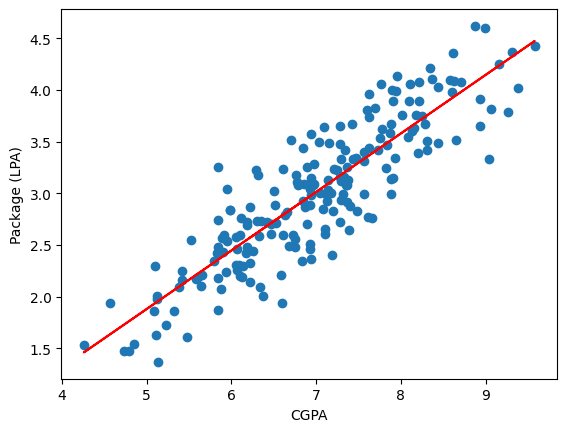

In [13]:
plt.scatter(df.cgpa, df.package)
plt.plot(x_train, lr.predict(x_train), color = 'red')
plt.xlabel('CGPA')
plt.ylabel('Package (LPA)')

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [17]:
mae = mean_absolute_error(y_test, pred)
mse = mean_squared_error(y_test, pred)

rmse = np.sqrt(mse)
r2score = r2_score(y_test, pred)

print(f'Mean Absolute Error: {mae}')
print(f'Mean Squared Error: {mse}')
print(f'Root Mean Square Error: {rmse}')
print(f'R2 Score: {r2score}')

Mean Absolute Error: 0.2117715170819035
Mean Squared Error: 0.0797161955617646
Root Mean Square Error: 0.28234056662435986
R2 Score: 0.8421117559037323


In [31]:
# Adjusted r2 score

adj_r2 = 1 - ((1-r2score)) * (40-1) / (40-1-1)
adj_r2

0.8379568021117253

(40, 1)